# Model B (Lightweight depthwise-separable CNN)


## 1. Setup
Same data, split, normalisation, optimizer (Adam, lr = 1e-3) and epoch count as Model A, so the comparison isolates the architecture.

In [ ]:

from a03_common import *     

EPOCHS = 25
LR = 1e-3

set_seed(SEED)
print("Device:", DEVICE)
data = Data(norm="dataset", batch_size=64, augment=True)
print("Train/Val/Test:", len(data.idx["train"]), len(data.idx["val"]), len(data.idx["test"]))
print("Classes:", data.classes)

Device: cpu
Train/Val/Test: 18900 4050 4050
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']



## 2. Architecture – Model B (Lightweight CNN)

### Depthwise Separable Convolution

Model B uses **Depthwise Separable Convolution** instead of standard convolution to reduce the number of parameters and computational cost.

It has two steps:

1. **Depthwise Convolution (3×3):** Applies a separate filter to each input channel to extract features.
2. **Pointwise Convolution (1×1):** Combines information from different channels.

This method requires fewer calculations than standard convolution, making it suitable for low-resource devices.

### Network Architecture

The input image size is **64×64×3**, and the model classifies images into **10 classes**.

| Layer | Output Size | Parameters |
|---|---|---:|
| DSConv1 + MaxPool | 32×32×32 | 193 |
| DSConv2 + MaxPool | 16×16×64 | 2,528 |
| DSConv3 | 16×16×128 | 9,152 |
| DSConv4 + MaxPool | 8×8×128 | 18,048 |
| DSConv5 + MaxPool | 4×4×256 | 34,688 |
| Global Average Pooling | 256 | 0 |
| Fully Connected Layer | 10 classes | 2,570 |
| **Total** | | **67,179** |

The model contains **67,179 trainable parameters**, which is below the assignment limit of 100,000.

### Design Choices

- **ReLU6:** A simple activation function that limits outputs between 0 and 6. It is computationally efficient.
- **Batch Normalization:** Helps stabilize training and can be combined with convolution layers during inference.
- **Max Pooling:** Reduces image dimensions and computational requirements.
- **Global Average Pooling:** Reduces the number of parameters compared with a large fully connected layer.
- **Depthwise Separable Convolution:** Reduces memory usage and computational cost.

### Why Model B Is Suitable for Edge Devices

Model B is designed to use fewer parameters, less memory, and fewer calculations than a standard CNN.

Therefore, it is more suitable for resource-constrained devices such as Raspberry Pi and embedded systems.

### Comparison with Model A

Model A uses standard convolution layers, while Model B uses depthwise separable convolution layers.

Model B also uses ReLU6, Batch Normalization, and Global Average Pooling. Therefore, differences in performance are not caused by convolution type alone.


In [3]:
set_seed(SEED)
modelB = ModelB(data.num_classes, 3).to(DEVICE)
print(modelB)
print()
total_params, total_macs = summarize(modelB)

n_total, n_trainable = count_params(modelB)
print(f"\nTrainable parameters: {n_trainable:,}  (limit 100,000)")
assert n_trainable <= 100_000, "Model B exceeds the 100k parameter limit!"
if data.num_classes == 10:
    assert n_trainable == 67_179, "Does not match the hand calculation in the table"
print("Constraint satisfied (<= 100,000) and matches the hand calculation.")

ModelB(
  (features): Sequential(
    (0): DSConv(
      (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
      (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DSConv(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)


**How much did the depthwise-separable factorisation save?** The cell below recomputes what *the same layer widths* would cost as standard 3x3 convolutions, which is a clean number for the report.

In [4]:
size = IMG_SIZE
std_w = ds_w = std_macs = ds_macs = 0
for m in modelB.features:
    if isinstance(m, DSConv):
        cin, cout = m[0].in_channels, m[3].out_channels
        std_w += 9 * cin * cout;            ds_w += 9 * cin + cin * cout
        std_macs += size * size * 9 * cin * cout
        ds_macs += size * size * (9 * cin + cin * cout)
    elif isinstance(m, nn.MaxPool2d):
        size //= 2
print(f"Conv weights  : standard {std_w:>10,} | depthwise separable {ds_w:>8,} | {std_w/ds_w:.1f}x fewer")
print(f"Conv MACs     : standard {std_macs:>10,} | depthwise separable {ds_macs:>8,} | {std_macs/ds_macs:.1f}x fewer")

Conv weights  : standard    535,392 | depthwise separable   62,683 | 8.5x fewer
Conv MACs     : standard 97,910,784 | depthwise separable 11,800,576 | 8.3x fewer


## 3. Training
Adam (lr = 1e-3), cross-entropy, 25 epochs, best-validation checkpoint (the test set is never used for selection).

In [5]:
set_seed(SEED)
modelB = ModelB(data.num_classes, 3).to(DEVICE)
optB = torch.optim.Adam(modelB.parameters(), lr=LR)
histB = train_model(modelB, optB, data, epochs=EPOCHS, name="Model B / Adam")

[Model B / Adam] epoch 01 | train loss 0.9439 acc 0.6569 | val loss 0.6696 acc 0.7598 | 128.7s
[Model B / Adam] epoch 02 | train loss 0.6330 acc 0.7759 | val loss 0.5902 acc 0.7822 | 136.8s
[Model B / Adam] epoch 03 | train loss 0.5234 acc 0.8168 | val loss 0.4679 acc 0.8306 | 136.9s
[Model B / Adam] epoch 04 | train loss 0.4620 acc 0.8376 | val loss 0.4511 acc 0.8442 | 136.3s
[Model B / Adam] epoch 05 | train loss 0.4174 acc 0.8521 | val loss 0.4428 acc 0.8481 | 437.0s
[Model B / Adam] epoch 06 | train loss 0.3689 acc 0.8763 | val loss 0.3721 acc 0.8681 | 158.1s
[Model B / Adam] epoch 07 | train loss 0.3490 acc 0.8778 | val loss 0.3095 acc 0.8933 | 170.8s
[Model B / Adam] epoch 08 | train loss 0.3101 acc 0.8923 | val loss 0.3025 acc 0.8938 | 168.6s
[Model B / Adam] epoch 09 | train loss 0.2898 acc 0.8999 | val loss 0.3178 acc 0.8857 | 168.8s
[Model B / Adam] epoch 10 | train loss 0.2718 acc 0.9041 | val loss 0.2920 acc 0.9007 | 167.1s
[Model B / Adam] epoch 11 | train loss 0.2526 acc 

## 4. Learning curves
Compare with Model A: does B converge more slowly or more smoothly? Is the train-validation gap smaller (B has fewer parameters and BN regularisation, so overfitting is usually milder)?

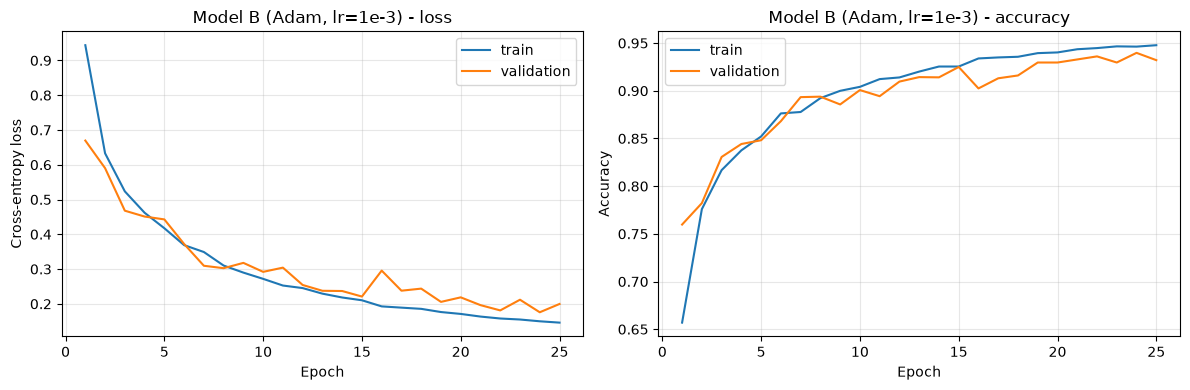

In [6]:
plot_history(histB, "Model B (Adam, lr=1e-3)", "modelB_curves.png")

### Learning Curves

The learning curves show how the training and validation losses change over 25 epochs. A decreasing training loss indicates that the CNN is learning from the training data. A decreasing validation loss indicates that the model is improving its performance on unseen data.

If both losses decrease and remain close to each other, the model is learning well with good generalization. If the validation loss starts increasing while the training loss continues decreasing, it indicates overfitting.

## 5. Test-set evaluation
Accuracy, macro precision/recall, per-class report and confusion matrix. Use the test set once, after training.

Test accuracy: 0.9432
Macro precision: 0.9428 | Macro recall: 0.9420 | Macro F1: 0.9419

                      precision    recall  f1-score   support

          AnnualCrop     0.9011    0.9311    0.9158       450
              Forest     0.9801    0.9844    0.9823       450
HerbaceousVegetation     0.9260    0.9178    0.9219       450
             Highway     0.9479    0.9227    0.9351       375
          Industrial     0.9667    0.9280    0.9469       375
             Pasture     0.9074    0.9800    0.9423       300
       PermanentCrop     0.9209    0.8693    0.8944       375
         Residential     0.9293    0.9933    0.9603       450
               River     0.9549    0.9040    0.9288       375
             SeaLake     0.9933    0.9889    0.9911       450

            accuracy                         0.9432      4050
           macro avg     0.9428    0.9420    0.9419      4050
        weighted avg     0.9437    0.9432    0.9430      4050



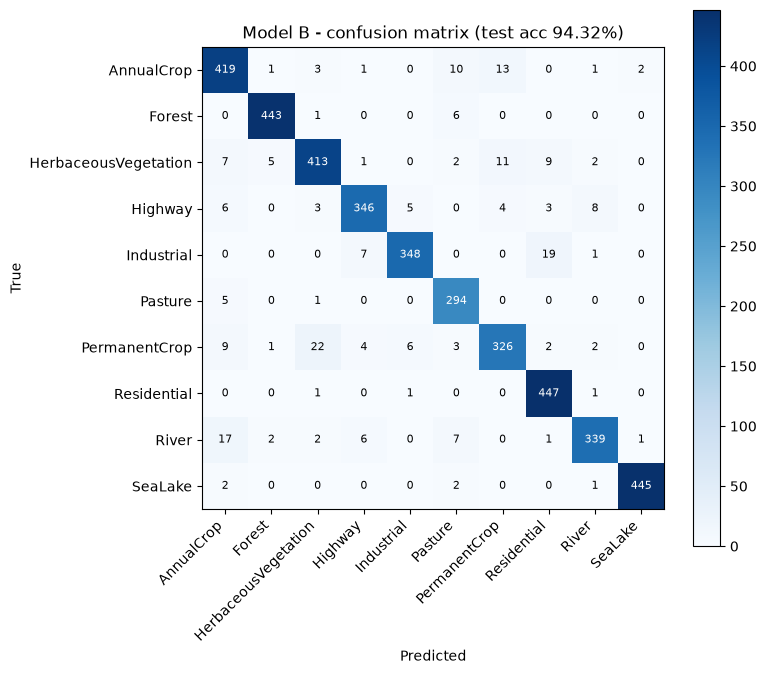

Most confused pairs (true -> predicted : count)
  PermanentCrop -> HerbaceousVegetation : 22
  Industrial -> Residential : 19
  River -> AnnualCrop : 17
  AnnualCrop -> PermanentCrop : 13
  HerbaceousVegetation -> PermanentCrop : 11


In [9]:
evB = evaluate(modelB, data)
cmB = plot_confusion(evB["y_true"], evB["y_pred"], data.classes,
                     f"Model B - confusion matrix (test acc {evB['acc']:.2%})", "modelB_confusion.png")

## 6. Deployment metrics and comparison with Model A
Size is the float32 `state_dict` file on disk. Latency is single-image CPU time on this laptop (relative comparison only). Everything is saved to `outputs/modelB_results.json`.

In [10]:
resB = save_results("modelB", "Model B (depthwise separable)", modelB, histB, evB,
                    "Adam lr=1e-3", data)

{
  "model": "Model B (depthwise separable)",
  "optimizer": "Adam lr=1e-3",
  "epochs": 25,
  "params": 67179,
  "trainable_params": 67179,
  "macs": 11803136,
  "size_kb": 286.8,
  "time_per_epoch_s": 601.2,
  "latency_ms_cpu": 5.87,
  "best_val_acc": 0.9397530864197531,
  "test_acc": 0.9432098765432099,
  "macro_precision": 0.9427643045565366,
  "macro_recall": 0.9419555555555557,
  "macro_f1": 0.9418857320269904
}


In [11]:
pa = OUT_DIR / "modelA_results.json"
if pa.exists():
    A = json.load(open(pa))
    rows = [("Parameters", A["params"], resB["params"], "{:,.0f}"),
            ("MACs", A["macs"], resB["macs"], "{:,.0f}"),
            ("Size on disk (KB)", A["size_kb"], resB["size_kb"], "{:,.1f}"),
            ("Time / epoch (s)", A["time_per_epoch_s"], resB["time_per_epoch_s"], "{:,.1f}"),
            ("CPU latency (ms/img)", A["latency_ms_cpu"], resB["latency_ms_cpu"], "{:,.2f}"),
            ("Test accuracy", A["test_acc"], resB["test_acc"], "{:.4f}")]
    print(f"{'Metric':<24}{'Model A':>14}{'Model B':>14}{'A / B':>10}")
    for name, a, bb, fmt in rows:
        print(f"{name:<24}{fmt.format(a):>14}{fmt.format(bb):>14}{a/bb:>10.2f}")
else:
    print("Run the Model A notebook first to see the side-by-side comparison.")

Metric                         Model A       Model B     A / B
Parameters                     914,122        67,179     13.61
MACs                        60,687,616    11,803,136      5.14
Size on disk (KB)              3,575.2         286.8     12.47
Time / epoch (s)                  55.8         601.2      0.09
CPU latency (ms/img)              3.62          5.87      0.62
Test accuracy                   0.9442        0.9432      1.00
